In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### CSV Data

In [2]:
data = pd.read_csv('data.csv')
data

,date,nat_demand,T2M_san,QV2M_san,TQL_san,W2M_san,E,absent
0,2019-05-23 15:00:00,1519.251075,29.892297,0.018181,0.266357,8.343299,339.231766,0
1,2019-05-23 16:00:00,1438.600325,28.922327,0.018540,0.274536,9.034458,96.636122,0
2,2019-05-23 17:00:00,1347.792450,27.828851,0.018914,0.269653,8.820997,24.009932,0
3,2019-05-23 18:00:00,1372.608725,26.814264,0.019318,0.274170,7.409496,1.332549,0
4,2019-05-23 19:00:00,1426.328300,26.347772,0.019524,0.247559,7.198770,0.000000,0
...,...,...,...,...,...,...,...,...
9489,2020-06-22 00:00:00,1072.810900,24.430200,0.018259,0.027008,2.513341,0.000000,0
9490,2020-06-22 01:00:00,1027.854700,24.198969,0.018083,0.032135,2.846843,0.000000,0
9491,2020-06-22 02:00:00,978.397800,24.033716,0.017900,0.035507,3.192699,0.000000,0
9492,2020-06-22 03:00:00,949.940100,23.886469,0.017701,0.032043,3.390905,0.000000,0


### NPY Data

In [3]:
true_data = np.load('true.npy')
pred_data = np.load('pred.npy')
true_data

array([[[ 1.51925110e+03,  2.98922977e+01,  1.81813184e-02,
          2.66357422e-01,  8.34329891e+00,  3.39231750e+02],
        [ 1.43860034e+03,  2.89223270e+01,  1.85399018e-02,
          2.74536133e-01,  9.03445816e+00,  9.66361084e+01],
        [ 1.34779248e+03,  2.78288517e+01,  1.89137310e-02,
          2.69653320e-01,  8.82099628e+00,  2.40099182e+01],
        ...,
        [ 1.50337720e+03,  2.87961063e+01,  1.82881318e-02,
          2.85278320e-01,  1.09038219e+01,  1.64643408e+03],
        [ 1.53090466e+03,  2.86786747e+01,  1.81431677e-02,
          2.78686523e-01,  1.12928181e+01,  1.63227563e+03],
        [ 1.51233252e+03,  2.84402714e+01,  1.80439875e-02,
          2.51953125e-01,  1.12712231e+01,  1.12046631e+03]],

       [[ 1.43860034e+03,  2.89223270e+01,  1.85399018e-02,
          2.74536133e-01,  9.03445816e+00,  9.66361084e+01],
        [ 1.34779248e+03,  2.78288517e+01,  1.89137310e-02,
          2.69653320e-01,  8.82099628e+00,  2.40099182e+01],
        [ 1.37260

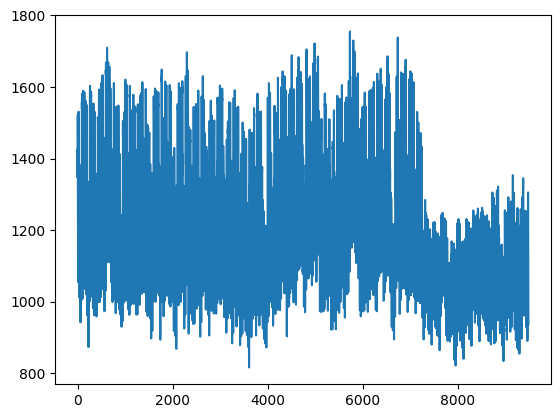

In [13]:
# 折线图
plt.plot(data['nat_demand'], '-')
plt.show()

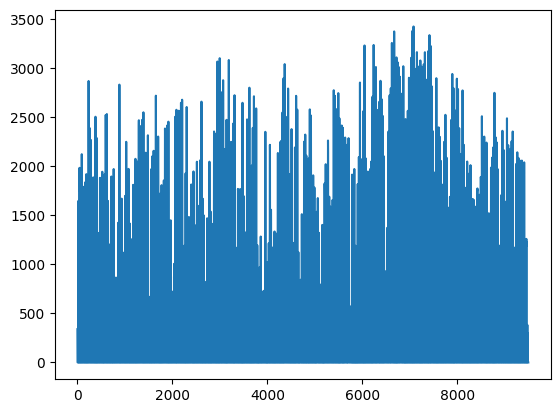

In [14]:
plt.plot(data['E'], '-')

In [8]:
absent = np.zeros(len(data), dtype=int)
start = 0
for i in range(start, len(data), 790):
    j = i + 790
    # 产生 5个随机数
    start_absent = np.random.randint(i, j, 5)
    # 每个随机数延长随机的时间( 时间小于24小时)
    end_absent = np.random.randint(0, 24, 5) + start_absent
    for start_absent, end_absent in zip(start_absent, end_absent):
        absent[start_absent: end_absent] = 1
data.loc[:, 'absent'] = absent
data.to_csv('data1.csv', index=False)

In [20]:
t_mean = true_data[:,:,-1].mean()
p_mean = pred_data[:,:,-1].mean()
p_mean / t_mean

0.96161586

In [ ]:
data['date'].dt.strftime('%Y-%m-%d %H:%M:%S')

AttributeError: Can only use .dt accessor with datetimelike values

In [21]:
date = pd.to_datetime(data['date'])
data['date'] = date.dt.strftime('%Y-%m-%d %H:%M:%S')
data.to_csv('data1.csv', index=False)

,date,nat_demand,T2M_san,QV2M_san,TQL_san,W2M_san,E,absent
0,2019-05-23 15:00:00,1519.251075,29.892297,0.018181,0.266357,8.343299,339.231766,0
1,2019-05-23 16:00:00,1438.600325,28.922327,0.018540,0.274536,9.034458,96.636122,0
2,2019-05-23 17:00:00,1347.792450,27.828851,0.018914,0.269653,8.820997,24.009932,0
3,2019-05-23 18:00:00,1372.608725,26.814264,0.019318,0.274170,7.409496,1.332549,0
4,2019-05-23 19:00:00,1426.328300,26.347772,0.019524,0.247559,7.198770,0.000000,0
...,...,...,...,...,...,...,...,...
9489,2020-06-22 00:00:00,1072.810900,24.430200,0.018259,0.027008,2.513341,0.000000,0
9490,2020-06-22 01:00:00,1027.854700,24.198969,0.018083,0.032135,2.846843,0.000000,0
9491,2020-06-22 02:00:00,978.397800,24.033716,0.017900,0.035507,3.192699,0.000000,0
9492,2020-06-22 03:00:00,949.940100,23.886469,0.017701,0.032043,3.390905,0.000000,0


<function matplotlib.pyplot.show(close=None, block=None)>

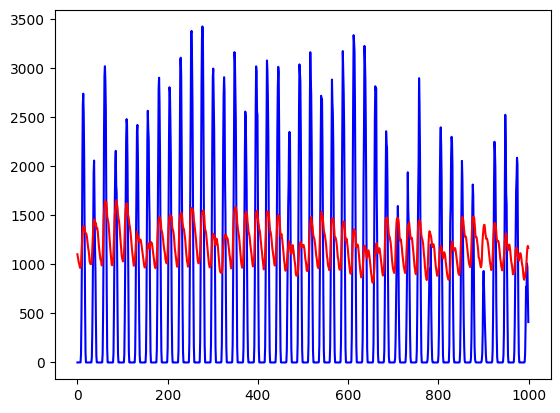

In [11]:
plt.plot(true_data[6800:7800,0,-1], label='pred_electricity', color='blue')
plt.plot(pred_data[6800:7800,0,0], label='pred_demand', color='red')
plt.show